# Actividad Fundamental 5: Procesamiento de datos
**Integrantes del equipo:**
* Angel Yahel Medina Herrera - 2102879
* Mario Alberto Tovanche Casillas - 2024432
* Jose Israel Bautista Rivera - 2127857
* Carlos Segura Cedillo - 2044463
* Humberto Jasso Valadez - 2070160

**Dia y Hora Clase:** Jueves - N1

#### **Ejercicio 1**
### 1. Importación de librerías y carga del dataset
Se utilizan Pandas para la manipulación de datos, NumPy para operaciones numéricas y Matplotlib para la visualización. Cargamos el archivo CSV directamente desde su versión 'raw' en GitHub.

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Usamos el enlace 'raw' de GitHub para que Pandas pueda leer el CSV correctamente
url = "https://raw.githubusercontent.com/dilp90/InteligenciaArtificial_y_RedesNeuronales_UANL_FIME/main/MachineLearning/Datasets/robot_sensors.csv"

# Cargar el dataset
df = pd.read_csv(url)

# Mostrar las primeras filas del dataset
print("Primeras filas del dataset original:")
display(df.head())

Primeras filas del dataset original:


,Tiempo (s),Distancia (cm),Velocidad (cm/s),Temperatura (°C)
0,0,43.708611,9.256646,23.925585
1,1,95.564288,27.095047,23.704682
2,2,75.879455,43.647292,33.593819
3,3,63.879264,36.611244,23.743193
4,4,24.041678,40.328057,24.079246


### 2. Limpieza de datos
Eliminaremos las filas que contengan valores nulos (`NaN`) y filtraremos los valores atípicos. En este caso, asumimos que una velocidad negativa es un error del sensor, por lo que nos quedaremos solo con velocidades mayores o iguales a cero.

In [14]:
# Mostrar tamaño original
print(f"Tamaño original: {df.shape}")

# 1. Eliminar filas con valores nulos
df_clean = df.dropna()

# 2. Filtrar valores atípicos (Velocidad negativa)
# Nota: Ajusta el nombre de la columna si en el CSV viene escrito ligeramente distinto.
nombre_col_velocidad = 'Velocidad (cm/s)'
df_clean = df_clean[df_clean[nombre_col_velocidad] >= 0]

print(f"Tamaño después de limpieza: {df_clean.shape}")

Tamaño original: (1000, 4)
Tamaño después de limpieza: (913, 4)


### 3. Normalización de los datos (Min-Max Scaling)
Aplicaremos la fórmula de Min-Max Scaling: `(X - min) / (max - min)`. Esto transformará todos los valores de los sensores a una escala entre 0 y 1, permitiendo comparar métricas que originalmente tenían magnitudes muy distintas.

In [15]:
# Guardamos la columna de tiempo para no normalizarla y usarla como eje X
tiempo = df_clean['Tiempo (s)']

# Seleccionamos solo las columnas de los sensores a normalizar
columnas_sensores = ['Distancia (cm)', 'Velocidad (cm/s)', 'Temperatura (°C)']
df_sensores = df_clean[columnas_sensores]

# Aplicar Min-Max Scaling manualmente usando pandas
df_norm = (df_sensores - df_sensores.min()) / (df_sensores.max() - df_sensores.min())

# Reintegramos el tiempo al dataframe normalizado
df_norm.insert(0, 'Tiempo (s)', tiempo)

print("Datos normalizados:")
display(df_norm.head())

Datos normalizados:


,Tiempo (s),Distancia (cm),Velocidad (cm/s),Temperatura (°C)
0,0,0.371735,0.182609,0.262269
1,1,0.950755,0.540740,0.247509
2,2,0.730954,0.873049,0.908233
3,3,0.596960,0.731791,0.250082
4,4,0.152134,0.806411,0.272535


### 4. Visualización de datos
Graficaremos las tres variables de los sensores en el tiempo. Al estar normalizadas (todas entre 0 y 1), podemos verlas en la misma gráfica sin que una opaque a las demás por su escala.

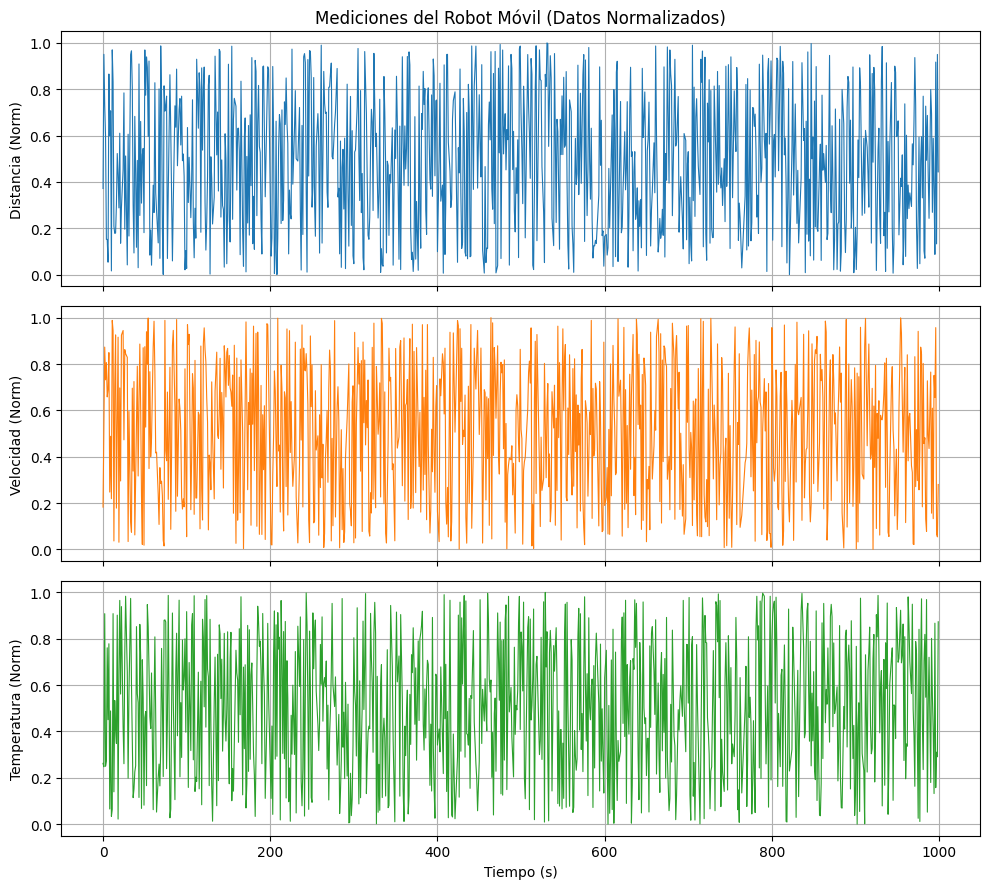

In [16]:
fig, axs = plt.subplots(3, 1, figsize=(10, 9), sharex=True)

axs[0].plot(df_norm['Tiempo (s)'], df_norm['Distancia (cm)'], color='tab:blue', linewidth=0.8)
axs[0].set_ylabel('Distancia (Norm)')
axs[0].set_title('Mediciones del Robot Móvil (Datos Normalizados)')
axs[0].grid(True)

axs[1].plot(df_norm['Tiempo (s)'], df_norm['Velocidad (cm/s)'], color='tab:orange', linewidth=0.8)
axs[1].set_ylabel('Velocidad (Norm)')
axs[1].grid(True)

axs[2].plot(df_norm['Tiempo (s)'], df_norm['Temperatura (°C)'], color='tab:green', linewidth=0.8)
axs[2].set_ylabel('Temperatura (Norm)')
axs[2].set_xlabel('Tiempo (s)')
axs[2].grid(True)

plt.tight_layout()
plt.show()

#### **Ejercicio 2. Preguntas**

### 1. ¿Cómo afecta la limpieza de datos al análisis del dataset?

La limpieza de datos incide directamente en la confiabilidad de cualquier análisis posterior. Al eliminarse los valores nulos y las lecturas con velocidad negativa (consideradas errores del sensor), el conjunto de datos se redujo de 1000 a 913 filas, es decir, se descartó cerca del 8.7% de los registros. Sin este proceso, los valores faltantes habrían generado errores de cálculo o resultados sesgados en las estadísticas descriptivas (mínimos, máximos y promedios), mientras que las lecturas atípicas habrían distorsionado la escala real de los datos, afectando en particular a la normalización Min-Max, cuyo resultado depende directamente de los valores extremos del conjunto. En consecuencia, la limpieza asegura que las conclusiones obtenidas reflejen el comportamiento real del robot y no artefactos producidos por fallas de medición.

### 2. ¿Por qué es importante la normalización en Machine Learning?

La normalización es relevante porque las variables del dataset se encuentran en escalas distintas: la distancia se mide en centímetros con un rango amplio, la velocidad en cm/s y la temperatura en grados Celsius con un rango mucho más reducido. Si estas variables se emplearan sin normalizar en un modelo de Machine Learning, aquellas con mayor magnitud numérica dominarían el proceso de aprendizaje, sesgando el resultado independientemente de su verdadera importancia. Esto afecta particularmente a algoritmos basados en distancias (como KNN o K-Means) y a métodos de optimización por descenso de gradiente, donde escalas dispares ralentizan o dificultan la convergencia. Al aplicar Min-Max Scaling, todas las variables quedan expresadas en un rango común de 0 a 1, permitiendo que cada sensor contribuya de forma equilibrada al modelo.

### 3. ¿Cómo interpretarías los datos visualizados?

En la gráfica se observa que las tres variables normalizadas (distancia, velocidad y temperatura) oscilan de manera prácticamente constante a lo largo de todo el rango de tiempo, sin mostrar una tendencia clara de crecimiento, decrecimiento o estabilización. Este comportamiento sugiere que las lecturas de los sensores no siguen un patrón continuo o predecible, sino que se comportan como ruido aleatorio distribuido de forma relativamente uniforme entre 0 y 1. Esto es consistente con el hecho de que el dataset está compuesto por datos ficticios generados con fines didácticos, y no por mediciones reales de un robot en movimiento continuo, donde normalmente existiría cierta correlación temporal (por ejemplo, cambios graduales de temperatura o desaceleración progresiva al acercarse a un obstáculo). La ausencia de dicha correlación es, en sí misma, la principal observación que puede extraerse de la visualización.